# GSM8K all model sweep

Two views of the same completed, matched 1,536-problem training-subset results. These cells only plot saved summaries; they do not launch inference or change scoring.

**Full figure:** retains all sixteen models, including DeepSeek-R1-Distill-Qwen-1.5B and incomplete-grid gaps.

**Appendix figure:** omits Qwen-R1 1.5B at the user's request because its observed GSM8K baseline score is lower than the general Qwen comparison. This is a presentation-selected subset, not a complete model survey. The full figure remains available here. General Qwen Instruct is not the R1 model's immediate training parent.

Each curve uses its own alpha=1 baseline; fitted-prior versus random-control curve separation is not itself a paired causal contrast across hardware runs. Whiskers are paired Wald **±1 SE**, not 95% confidence intervals. Missing settings stay missing; values below −20% are clipped, not removed from the source data.


The four added small-model sweeps cover α=0.50–1.20 in steps of 0.05, with 70% vocabulary coverage and greedy BF16 decoding. Qwen3 and Qwen3.5 use non-thinking mode. No random-control results exist for these four; no control curve or head-to-head control test is imputed. All curves are exploratory training-subset results; peak-selected p-values are descriptive and unadjusted for selecting α.

Qwen3-8B and Gemma-3-12B fitted and random-control sweeps are complete across α=0.40–1.20 in steps of 0.05, with 1,536 predictions per setting. Controls use one isotropic Gaussian unit direction per model (seed 20260913), not perturbation-norm matching. Existing fitted results and the direction-independent α=1 control were reused with provenance. Qwen2.5-7B retains its fitted-only α=0.50–1.20 sweep. Peaks and paired p-values remain exploratory and unadjusted for alpha selection.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

cwd = Path.cwd().resolve()
root = next(p for p in (cwd, cwd.parent) if (p / 'prior_calibration/data/all_model_sweep_curves.json').exists())
research = root / 'prior_calibration'
sys.path.insert(0, str(research))
from all_model_plot_style import draw, baseline_subtitle, limits
fitted_data = json.loads((research / 'data/all_model_sweep_curves.json').read_text())
control_data = json.loads((research / 'data/all_model_random_controls_streaming.json').read_text())
curves = {c['key']: c for c in fitted_data['curves']}
small_data = json.loads((research / 'data/small_model_sweep_curves_20260928.json').read_text())
curves.update({c['key']: c for c in small_data['curves']})
large_data = json.loads((research / 'data/large_model_sweep_curves_20260930.json').read_text())
curves.update({c['key']: c for c in large_data['curves']})
controls = {c['model']: c['settings'] for c in control_data['models']}
extended_data = json.loads((research / 'data/extended_controls_sweep_curves_20261007.json').read_text())
curves.update({c['key']: c for c in extended_data['curves']})
controls.update({c['model']: c['settings'] for c in extended_data['controls']})
control_data['updated'] = extended_data['updated']
export = root / 'notebook_plotters/plot_export'
export.mkdir(exist_ok=True)
figures_dir = export
assert figures_dir.is_dir(), figures_dir

# Presentation controls: no smoothing; common axes; paired Wald one-SE whiskers.
PRIOR_COLOR = '#246a98'
CONTROL_COLOR = '#bd3838'
LINE_WIDTH = 3
MARKER_SIZE = 5
FONT_SIZE = 11
Y_LIMITS = limits([c['settings'] for c in curves.values()] + list(controls.values()))
FULL_LAYOUT = [
    ['llama32_1b', 'llama32_3b', 'llama31_8b'],
    ['gemma3_270m', 'gemma3_1b', 'gemma3_4b'],
    ['qwen25_05b', 'qwen3_06b', 'qwen35_08b'],
    ['qwen_1p5b', 'qwen_math_1p5b', 'qwen_r1_1p5b'],
    ['qwen_3b', 'qwen25_7b', 'qwen3_8b'],
    ['gemma3_12b', None, None],
]
APPENDIX_LAYOUT = [
    ['llama32_1b', 'llama32_3b', 'llama31_8b'],
    ['qwen_1p5b', 'qwen_3b', 'qwen3_8b'],
    ['gemma3_1b', 'gemma3_4b', 'gemma3_12b'],
]
plt.rcParams.update({
    'font.size': FONT_SIZE,
    'axes.titlesize': FONT_SIZE,
    'axes.labelsize': FONT_SIZE,
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'legend.fontsize': FONT_SIZE,
    'figure.titlesize': FONT_SIZE,
    'pdf.fonttype': 42,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

def plot_sweeps(layout, stem, appendix=False, width=10, row_height=2.5, font_size=FONT_SIZE, save_dir=None):
    fig, axes = plt.subplots(len(layout), 3, figsize=(width, row_height * len(layout) + .45), dpi=200,
                             sharex=True, sharey=True, squeeze=False)
    # Below ~1.8 in per panel the full subtitle no longer fits at 10 pt; shorten its wording only.
    compact = width / 3 < 2.2
    included = []
    for row, keys in enumerate(layout):
        for col, key in enumerate(keys):
            ax = axes[row, col]
            if key is None:
                ax.set_visible(False)
                continue
            included.append(key)
            c = curves[key]
            assert c['n'] == 1536
            control = controls.get(key, [])
            draw(ax, c['settings'], color=PRIOR_COLOR, lw=LINE_WIDTH,
                 ms=MARKER_SIZE, marker='o', label='Fitted prior')
            if control:
                draw(ax, control, color=CONTROL_COLOR, lw=LINE_WIDTH,
                     ms=MARKER_SIZE, marker='s', ls='--', label='Random control')
            ax.axhline(0, color='.45', lw=.8)
            ax.axvline(1, color='.45', ls=':', lw=.8)
            ax.set(xlim=(.39, 1.21), ylim=Y_LIMITS)
            ax.set_xlabel('Prior multiplier α', fontsize=font_size)
            ax.set_xticks([.4, .6, .8, 1., 1.2])
            ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
            ax.grid(axis='y', alpha=.18)
            ax.tick_params(labelbottom=True, labelsize=font_size)
            model_label = c['label'].replace(' IT', ' Instruct')
            if key in {r['key'] for r in large_data['curves']} and c.get('partial', False):
                model_label += ' (ongoing)'
            subtitle = baseline_subtitle(c['settings'], control)
            if compact:
                subtitle = subtitle.replace('Baseline accuracy: ', 'Baseline: ')
            ax.set_title(model_label + '\n' + subtitle, fontsize=font_size)
            if col == 0:
                ax.set_ylabel('Relative error reduction', fontsize=font_size)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .99),
               ncol=2, frameon=False, fontsize=font_size)
    fig.tight_layout(rect=(0, 0, 1, .94))
    figure_export = Path(save_dir) if save_dir is not None else (figures_dir if appendix else export)
    figure_export.mkdir(parents=True, exist_ok=True)
    saved = []
    for ext in ('png', 'pdf'):
        path = figure_export / f'{stem}.{ext}'
        fig.savefig(path, dpi=200, bbox_inches='tight')
        saved.append(path)
    print('saved:', *[str(p) for p in saved], sep='\n  ')
    (export / f'{stem}.json').write_text(json.dumps({
        'included_models': included, 'excluded_models': sorted(set(curves) - set(included)),
        'source_control_update': control_data['updated'], 'metric': 'relative error reduction',
        'interval': 'paired Wald +/-1 SE', 'y_limits': list(Y_LIMITS),
        'exclusion_note': 'Appendix figure keeps Llama 3.2 1B/3B, Llama 3.1 8B, Qwen 2.5 1.5B Instruct, Qwen 2.5 3B Instruct, Qwen 3 8B, and Gemma 3 1B/4B/12B.' if appendix else None,
    }, indent=2))
    plt.show()
    return fig


## Full plot — all sixteen models


saved:
  /home/jl3499/LLM_dark_matter/direction_of_ignorance/notebook_plotters/plot_export/GSM8K_all_models_sweep_full.png
  /home/jl3499/LLM_dark_matter/direction_of_ignorance/notebook_plotters/plot_export/GSM8K_all_models_sweep_full.pdf


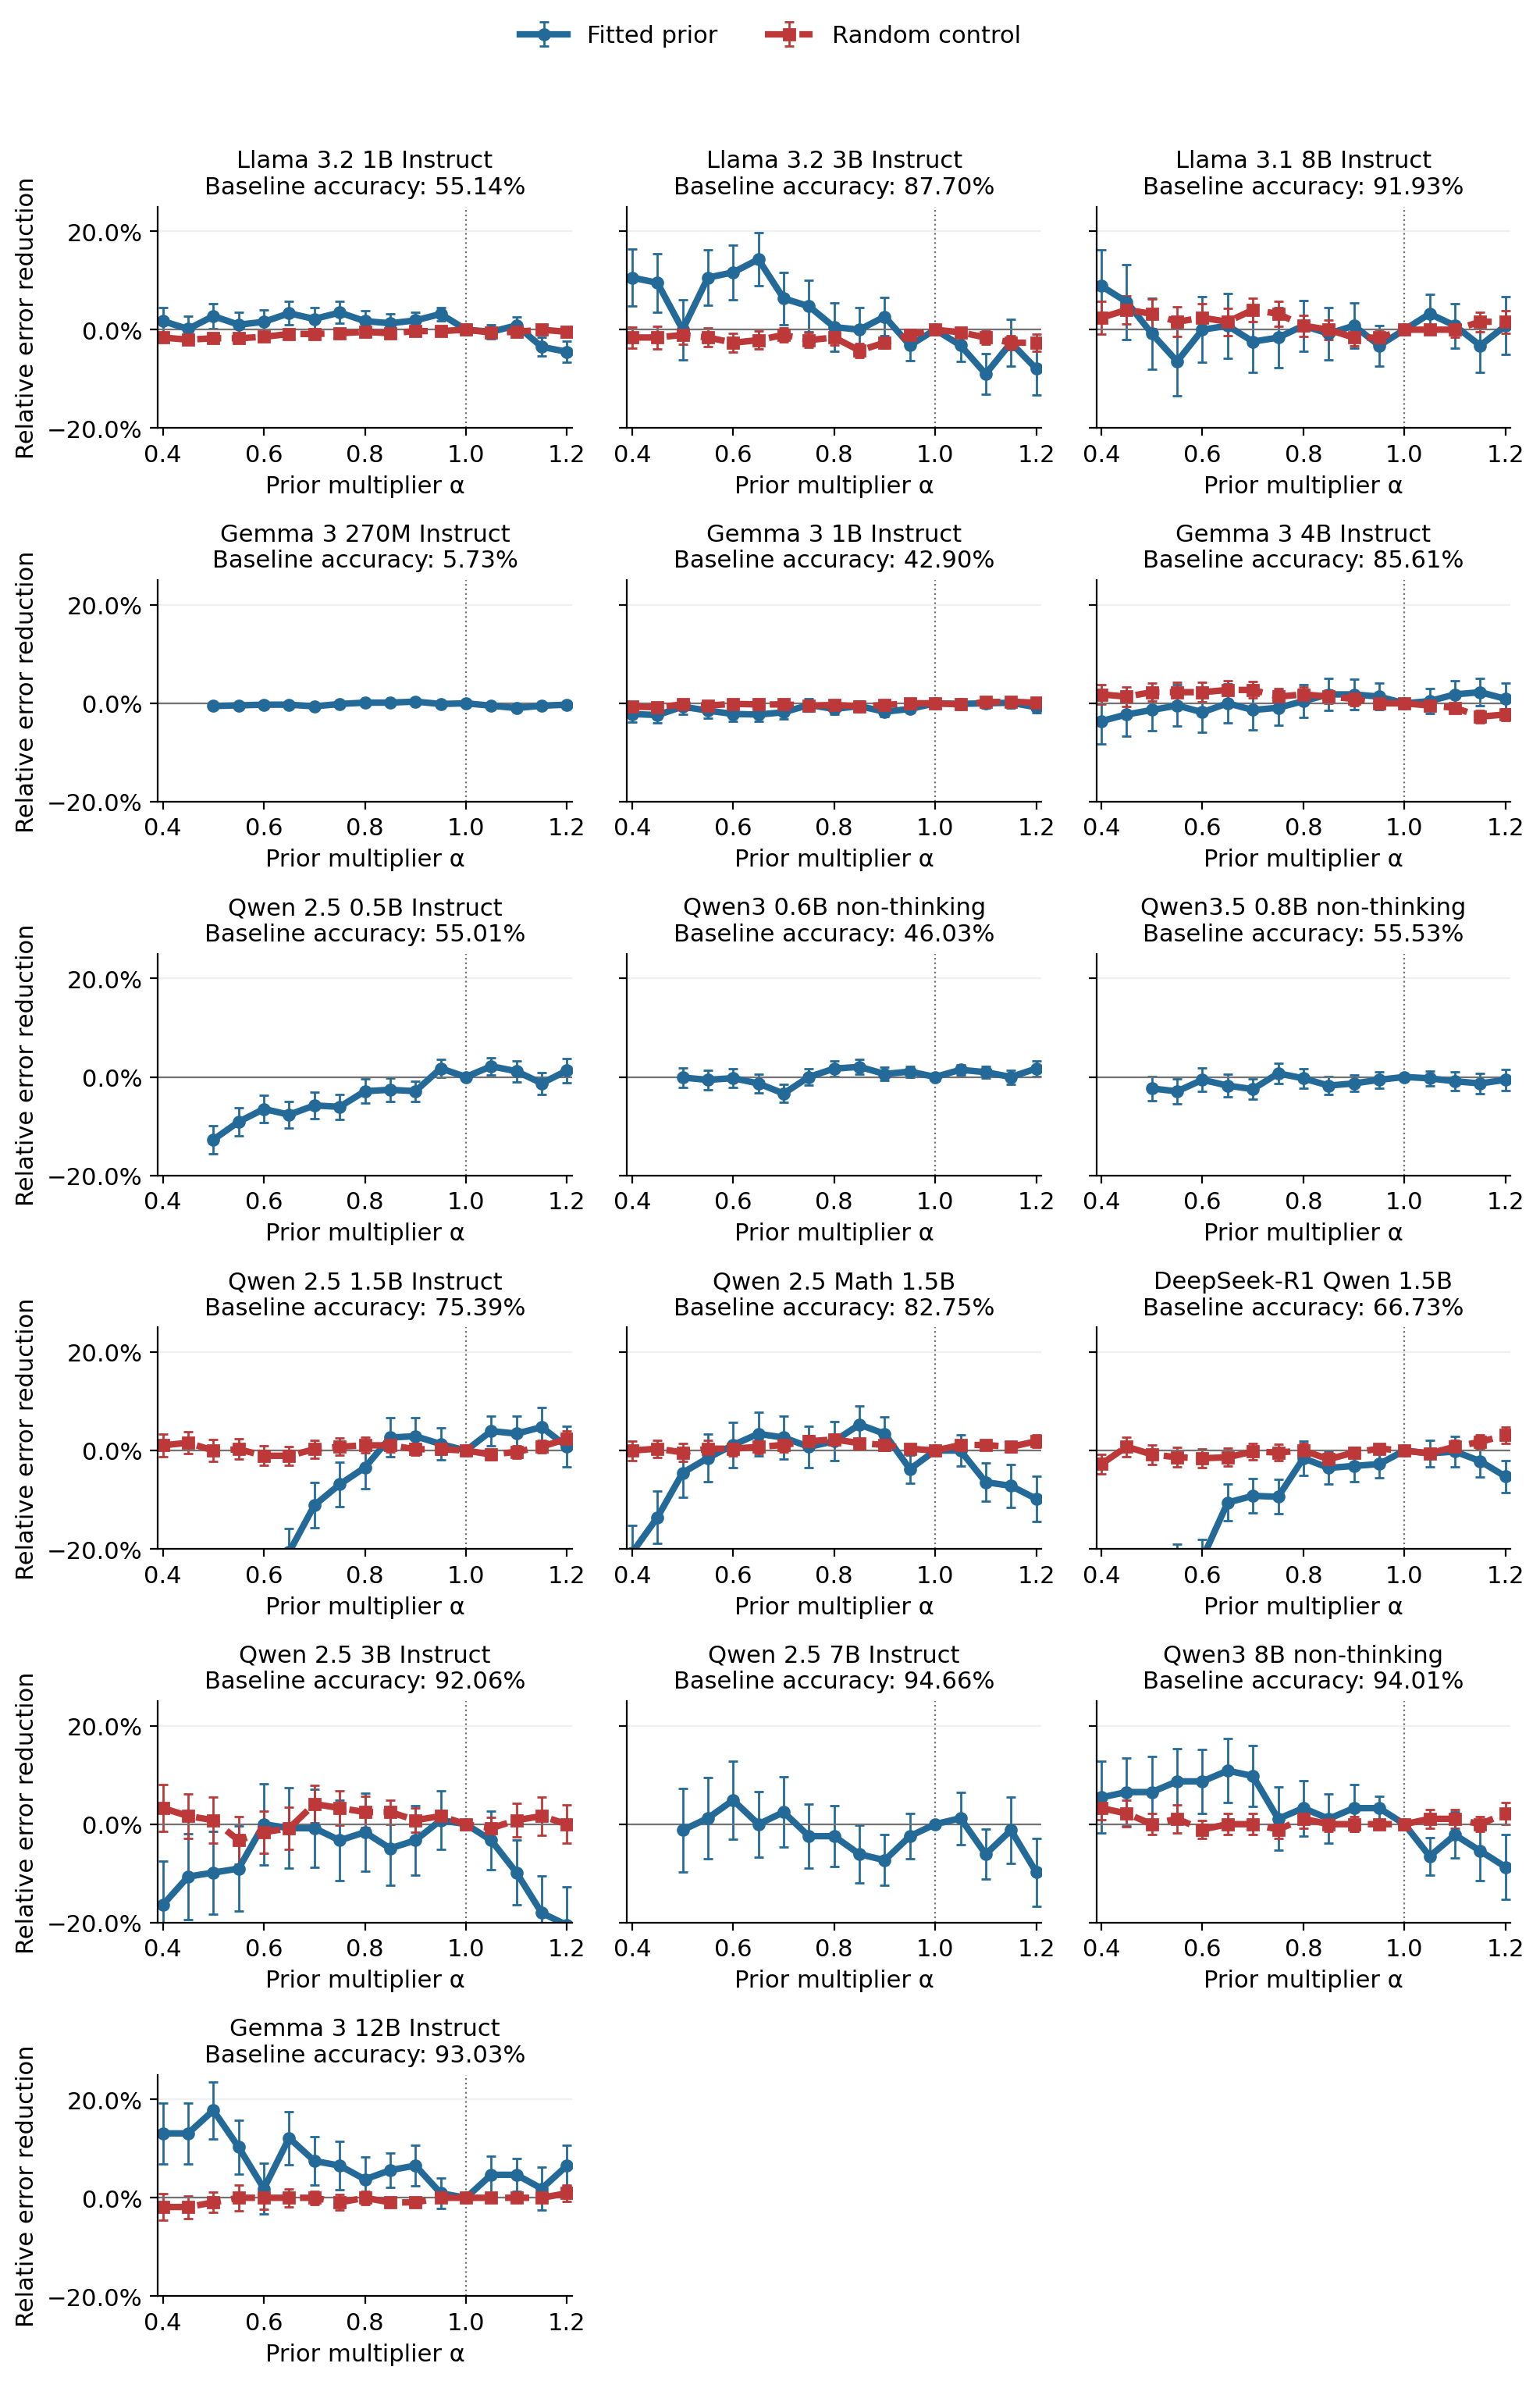

In [2]:
full_figure = plot_sweeps(FULL_LAYOUT, 'GSM8K_all_models_sweep_full')


*Caption.* All models use the same $n=1536$ training problems, greedy 8-shot chain-of-thought prompting, and unit-aware flexible scoring. Whiskers show paired Wald $\pm 1$ SE, not 95% confidence intervals; the baseline-error denominator is held fixed. Only completed settings are shown, without smoothing, and values below $-20\%$ are clipped.

## Appendix plot — ten models

Llama 3.2 1B and 3B, Llama 3.1 8B, Qwen 2.5 1.5B Instruct, Qwen 2.5 Math 1.5B, Qwen 2.5 3B Instruct, Qwen 3 8B, and Gemma 3 1B, 4B, and 12B. The displayed range, scores, confidence convention and common y-axis are unchanged.


saved:
  /home/jl3499/LLM_dark_matter/direction_of_ignorance/iclr2027/figures/GSM8K_all_models_sweep_appendix.png
  /home/jl3499/LLM_dark_matter/direction_of_ignorance/iclr2027/figures/GSM8K_all_models_sweep_appendix.pdf


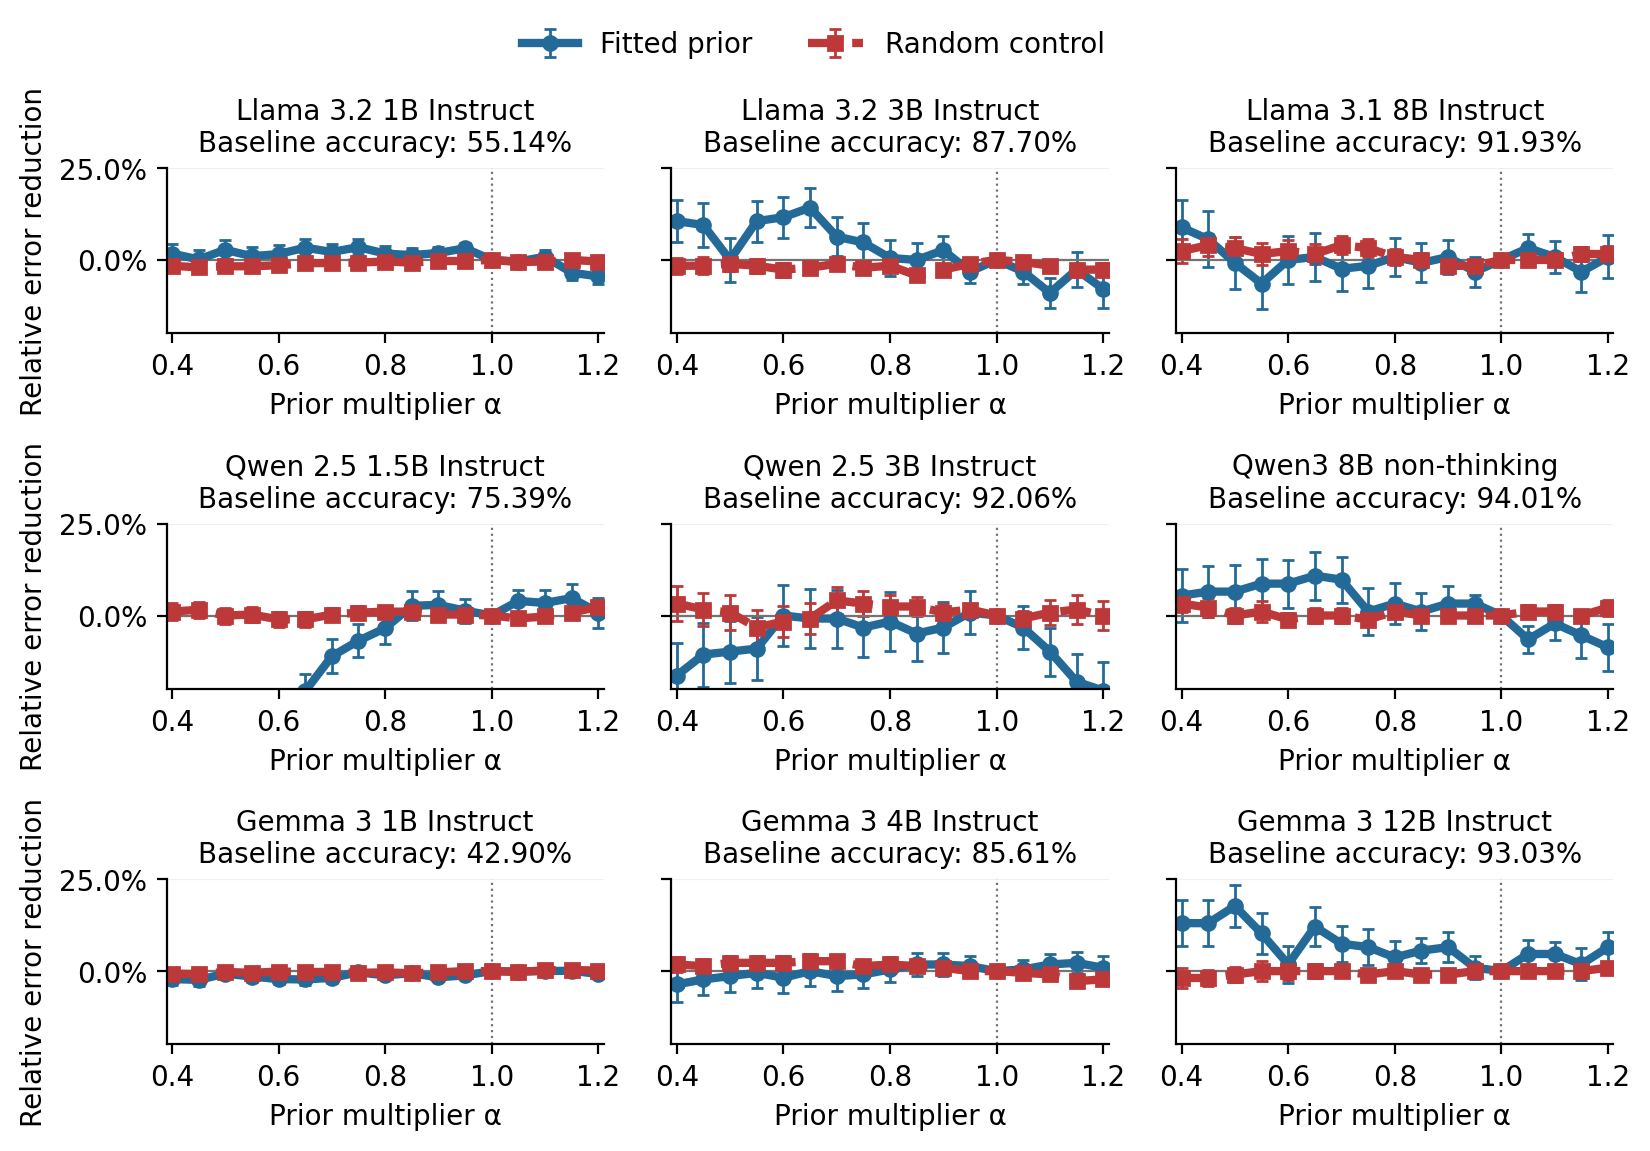

In [3]:
appendix_save_dir = export
appendix_figure = plot_sweeps(APPENDIX_LAYOUT, 'GSM8K_all_models_sweep_appendix', appendix=True,
                              width=8.5, row_height=1.8, font_size=10, save_dir=appendix_save_dir)


*Caption.* All models use the same $n=1536$ training problems, greedy 8-shot chain-of-thought prompting, and unit-aware flexible scoring. Whiskers show paired Wald $\pm 1$ SE, not 95% confidence intervals; the baseline-error denominator is held fixed. Only completed settings are shown, without smoothing, and values below $-20\%$ are clipped. 

## Peak improvement and paired significance

For each model in the appendix layout, the α with the largest net error reduction is selected from the available completed non-identity settings (α ≠ 1). Because each problem is scored under both the baseline and the intervention, the paired test is an exact McNemar test on the discordant pairs: `corrected` (baseline wrong → tuned right) against `broken` (baseline right → tuned wrong), two-sided, under H₀ that the two are equally likely. The Wald column is the same ±1 SE shown in the figure.

The reported p-value is the two-sided McNemar test at that peak α, with no correction for the choice of α.


In [4]:
from scipy.stats import binomtest
from IPython.display import Markdown, display
from all_model_plot_style import wald

def peak_row(key):
    c = curves[key]
    rows = [r for r in c['settings'] if .4 <= r['alpha'] <= 1.2 and abs(r['alpha'] - 1) > 1e-9]
    best = max(rows, key=lambda r: wald(r)[0])
    reduction, se = wald(best)
    n = best['n']
    corrected, broken = best['corrected'], best['broken']
    p = binomtest(corrected, corrected + broken, .5, alternative='two-sided').pvalue
    return {
        'Model': c['label'].replace(' IT', ' Instruct'),
        'Peak α': f"{best['alpha']:.2f}",
        'Baseline acc.': f"{100 * best['baseline_correct'] / n:.2f}%",
        'Tuned acc.': f"{100 * best['tuned_correct'] / n:.2f}%",
        'Corrected / broken': f"{corrected} / {broken}",
        'Net error reduction (±1 SE)': f"{reduction:+.1f}% ± {se:.1f}",
        'McNemar p': f"{p:.2g}",
        'Significant (p < 0.05)': 'yes' if p < .05 and corrected > broken else 'no',
    }

table_rows = [peak_row(k) for row in APPENDIX_LAYOUT for k in row if k is not None]
headers = list(table_rows[0])
markdown = '\n'.join([
    '| ' + ' | '.join(headers) + ' |',
    '|' + '|'.join('---' if h == 'Model' else '---:' for h in headers) + '|',
    *('| ' + ' | '.join(r[h] for h in headers) + ' |' for r in table_rows),
])
display(Markdown(markdown))
(export / 'GSM8K_all_models_sweep_peak_significance.md').write_text(markdown + '\n')
print(markdown)

| Model | Peak α | Baseline acc. | Tuned acc. | Corrected / broken | Net error reduction (±1 SE) | McNemar p | Significant (p < 0.05) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Llama 3.2 1B Instruct | 0.75 | 55.14% | 56.71% | 127 / 103 | +3.5% ± 2.2 | 0.13 | no |
| Llama 3.2 3B Instruct | 0.65 | 87.70% | 89.45% | 66 / 39 | +14.3% ± 5.4 | 0.011 | yes |
| Llama 3.1 8B Instruct | 0.40 | 91.93% | 92.64% | 47 / 36 | +8.9% ± 7.3 | 0.27 | no |
| Qwen 2.5 1.5B Instruct | 1.15 | 75.39% | 76.56% | 118 / 100 | +4.8% ± 3.9 | 0.25 | no |
| Qwen 2.5 3B Instruct | 0.95 | 92.06% | 92.12% | 27 / 26 | +0.8% ± 6.0 | 1 | no |
| Qwen3 8B non-thinking | 0.65 | 94.01% | 94.66% | 23 / 13 | +10.9% ± 6.5 | 0.13 | no |
| Gemma 3 1B Instruct | 1.15 | 42.90% | 42.97% | 49 / 48 | +0.1% ± 1.1 | 1 | no |
| Gemma 3 4B Instruct | 1.15 | 85.61% | 85.94% | 22 / 17 | +2.3% ± 2.8 | 0.52 | no |
| Gemma 3 12B Instruct | 0.50 | 93.03% | 94.27% | 29 / 10 | +17.8% ± 5.8 | 0.0034 | yes |

| Model | Peak α | Baseline acc. | Tuned acc. | Corrected / broken | Net error reduction (±1 SE) | McNemar p | Significant (p < 0.05) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Llama 3.2 1B Instruct | 0.75 | 55.14% | 56.71% | 127 / 103 | +3.5% ± 2.2 | 0.13 | no |
| Llama 3.2 3B Instruct | 0.65 | 87.70% | 89.45% | 66 / 39 | +14.3% ± 5.4 | 0.011 | yes |
| Llama 3.1 8B Instruct | 0.40 | 91.93% | 92.64% | 47 / 36 | +8.9% ± 7.3 | 0.27 | no |
| Qwen 2.5 1.5B Instruct | 1.15 | 75.39% | 76.56% | 118 / 100 | +4.8% ± 3.9 | 0.25 | no |
| Qwen 2.5 3B Instruct | 0.95 | 92.06% | 92.12% | 27 / 26 | +0.8% ± 6.0 | 1 | no |
| Qwen3 8B non-thinking | 0.65 | 94.01% | 94.66% | 23 / 13 | +10.9% ± 6.5 | 0.13 | no |
| Gemma 3 1B Instruct | 1.15 | 42.90% | 42.97% | 49 / 48 | +0.1% ± 1.1 | 1 | no |
| Gemma 3 4B Instruct | 1.15 | 85.61% | 85.94% | 22 / 17 | +2.3% ± 2.8 | 0.52 | no |
| Gemma 3 12B Instruct | 0.50 | 93.03% | 94.27% | 29 / 10 | +17.8% ± 5.8 | 0.0034 | yes |


## Random-direction control: peak improvement and paired significance

Same comparison as above, applied to the random-direction control instead of the fitted prior. For each appendix model, the α with the largest net error reduction is taken from the available completed non-identity settings, and the p-value is the two-sided exact McNemar test at that α, with no correction for the choice of α.

In [5]:
import sys
sys.path.insert(0, str(research / 'helpers'))
import rescore_units as scoring

def fitted_root(key):
    if key == 'llama32_3b':
        return research / 'equalized_3b_1536_v1'
    return research / curves[key]['source_paths'][0] / key

def random_root(key):
    if key in {'qwen3_8b', 'gemma3_12b'}:
        return research / next(c['source_path'] for c in extended_data['controls'] if c['model'] == key)
    if key == 'llama32_3b':
        return research / 'random_direction_3b_1536_v1/3b'
    return research / 'random_controls_all_1536_20260920_v1/cloud' / key / 'random' / key

def manifest_for(key):
    if key == 'llama32_3b':
        return research / 'equalized_3b_1536_v1/manifest.json'
    return research / curves[key]['source_paths'][0] / 'manifest.json'

def head_to_head(key):
    c = curves[key]
    rows = [r for r in c['settings'] if .4 <= r['alpha'] <= 1.2 and abs(r['alpha'] - 1) > 1e-9]
    best = max(rows, key=lambda r: wald(r)[0])
    alpha = best['alpha']
    docs = scoring.read(manifest_for(key))['examples']
    fitted = scoring.arm(fitted_root(key), alpha, docs)
    control = scoring.arm(random_root(key), alpha, docs)
    assert [r['question_sha256'] for r in fitted] == [r['question_sha256'] for r in control]
    fitted_correct = np.array([r['score']['unit_aware'] for r in fitted])
    control_correct = np.array([r['score']['unit_aware'] for r in control])
    lambda_only = int((fitted_correct & ~control_correct).sum())
    random_only = int((~fitted_correct & control_correct).sum())
    p = binomtest(lambda_only, lambda_only + random_only, .5, alternative='two-sided').pvalue
    random_at_alpha = next(r for r in controls[key] if abs(r['alpha'] - alpha) < 1e-9)
    fitted_gain, _ = wald(best)
    random_gain, _ = wald(random_at_alpha)
    return {
        'Model': c['label'].replace(' IT', ' Instruct'),
        'Best α': f'{alpha:.2f}',
        'Lambda gain': f'{fitted_gain:+.1f}%',
        'Random gain': f'{random_gain:+.1f}%',
        'Gain difference': f'{fitted_gain - random_gain:+.1f} pp',
        'Lambda only / random only': f'{lambda_only} / {random_only}',
        'McNemar p': f'{p:.2g}',
        'Lambda gains more (p < 0.05)': 'yes' if p < .05 and lambda_only > random_only else 'no',
    }

head_rows = [head_to_head(k) for row in APPENDIX_LAYOUT for k in row if k is not None and controls.get(k)]
head_headers = list(head_rows[0])
head_markdown = '\n'.join([
    '| ' + ' | '.join(head_headers) + ' |',
    '|' + '|'.join('---' if h == 'Model' else '---:' for h in head_headers) + '|',
    *('| ' + ' | '.join(r[h] for h in head_headers) + ' |' for r in head_rows),
])
display(Markdown(head_markdown))
(export / 'GSM8K_all_models_sweep_lambda_vs_random.md').write_text(head_markdown + '\n')
print(head_markdown)


| Model | Best α | Lambda gain | Random gain | Gain difference | Lambda only / random only | McNemar p | Lambda gains more (p < 0.05) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Llama 3.2 1B Instruct | 0.75 | +3.5% | -0.7% | +4.2 pp | 129 / 100 | 0.064 | no |
| Llama 3.2 3B Instruct | 0.65 | +14.3% | -2.1% | +16.4 pp | 70 / 39 | 0.0039 | yes |
| Llama 3.1 8B Instruct | 0.40 | +8.9% | +2.4% | +6.5 pp | 47 / 39 | 0.45 | no |
| Qwen 2.5 1.5B Instruct | 1.15 | +4.8% | +0.8% | +4.0 pp | 113 / 98 | 0.34 | no |
| Qwen 2.5 3B Instruct | 0.95 | +0.8% | +1.6% | -0.8 pp | 26 / 27 | 1 | no |
| Qwen3 8B non-thinking | 0.65 | +10.9% | +0.0% | +10.9 pp | 23 / 13 | 0.13 | no |
| Gemma 3 1B Instruct | 1.15 | +0.1% | +0.3% | -0.2 pp | 45 / 47 | 0.92 | no |
| Gemma 3 4B Instruct | 1.15 | +2.3% | -2.7% | +5.0 pp | 27 / 16 | 0.13 | no |
| Gemma 3 12B Instruct | 0.50 | +17.8% | -0.9% | +18.7 pp | 30 / 10 | 0.0022 | yes |

| Model | Best α | Lambda gain | Random gain | Gain difference | Lambda only / random only | McNemar p | Lambda gains more (p < 0.05) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Llama 3.2 1B Instruct | 0.75 | +3.5% | -0.7% | +4.2 pp | 129 / 100 | 0.064 | no |
| Llama 3.2 3B Instruct | 0.65 | +14.3% | -2.1% | +16.4 pp | 70 / 39 | 0.0039 | yes |
| Llama 3.1 8B Instruct | 0.40 | +8.9% | +2.4% | +6.5 pp | 47 / 39 | 0.45 | no |
| Qwen 2.5 1.5B Instruct | 1.15 | +4.8% | +0.8% | +4.0 pp | 113 / 98 | 0.34 | no |
| Qwen 2.5 3B Instruct | 0.95 | +0.8% | +1.6% | -0.8 pp | 26 / 27 | 1 | no |
| Qwen3 8B non-thinking | 0.65 | +10.9% | +0.0% | +10.9 pp | 23 / 13 | 0.13 | no |
| Gemma 3 1B Instruct | 1.15 | +0.1% | +0.3% | -0.2 pp | 45 / 47 | 0.92 | no |
| Gemma 3 4B Instruct | 1.15 | +2.3% | -2.7% | +5.0 pp | 27 / 16 | 0.13 | no |
| Gemma 3 12B Instruct | 0.50 | +17.8% | -0.9% | +18.7 pp | 30 / 10 | 0.0022 | yes |
